# Model 1 information

Model 1 included ClosePrice, which is only known after the auction has ended. As a result, it is not a good predictor for new auctions, as it causes data leakage.

As a result, model 2 will drop this predictor form the decision tree, while keeping all other predictors. 

The same data, splitting criteria, and other aspects will be considered to ensure consistency between the models.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

In [3]:
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv').squeeze('columns')
y_test = pd.read_csv('y_test.csv').squeeze('columns')

FileNotFoundError: [Errno 2] No such file or directory: 'X_train.csv'

In [ ]:
# Checking training and testing data predictor shapes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
# Checking available predictors
print("\nPredictors:")
print(X_train.columns.tolist())
# Checking target distribution
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

# Checking X_train head
X_train.head()

Training data: (1183, 36)
Testing data: (789, 36)

Predictors:
['sellerRating', 'ClosePrice', 'OpenPrice', 'Category_Antique/Art/Craft', 'Category_Automotive', 'Category_Books', 'Category_Business/Industrial', 'Category_Clothing/Accessories', 'Category_Coins/Stamps', 'Category_Collectibles', 'Category_Computer', 'Category_Electronics', 'Category_EverythingElse', 'Category_Health/Beauty', 'Category_Home/Garden', 'Category_Jewelry', 'Category_Music/Movie/Game', 'Category_Photography', 'Category_Pottery/Glass', 'Category_SportingGoods', 'Category_Toys/Hobbies', 'Currency_EUR', 'Currency_GBP', 'Currency_US', 'Duration_1', 'Duration_3', 'Duration_5', 'Duration_7', 'Duration_10', 'endDay_Sun', 'endDay_Mon', 'endDay_Tue', 'endDay_Wed', 'endDay_Thu', 'endDay_Fri', 'endDay_Sat']

Training target distribution:
Competitive
1    0.540152
0    0.459848
Name: proportion, dtype: float64

Testing target distribution:
Competitive
1    0.541191
0    0.458809
Name: proportion, dtype: float64


,sellerRating,ClosePrice,OpenPrice,Category_Antique/Art/Craft,Category_Automotive,Category_Books,Category_Business/Industrial,Category_Clothing/Accessories,Category_Coins/Stamps,Category_Collectibles,...,Duration_5,Duration_7,Duration_10,endDay_Sun,endDay_Mon,endDay_Tue,endDay_Wed,endDay_Thu,endDay_Fri,endDay_Sat
0,4390.0,41.49,41.49,1,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
1,1155.0,8.99,8.99,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
2,2046.0,7.50,7.50,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
3,1266.0,6.79,6.79,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
4,1364.0,30.95,30.95,0,1,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0


In [ ]:
y_test.head(5)

0    1
1    1
2    1
3    0
4    1
Name: Competitive, dtype: int64

In [ ]:
# Excluding ClosePrice from the data
X_train_model2 = X_train.drop(columns=['ClosePrice'])
X_test_model2 = X_test.drop(columns=['ClosePrice'])

In [ ]:
# Verifying the remaining predictors
print("Training data:", X_train_model2.shape)
print("Testing data:", X_test_model2.shape)
print("\nRemaining predictors:")
print(X_train_model2.columns.tolist())

Training data: (1183, 35)
Testing data: (789, 35)

Remaining predictors:
['sellerRating', 'OpenPrice', 'Category_Antique/Art/Craft', 'Category_Automotive', 'Category_Books', 'Category_Business/Industrial', 'Category_Clothing/Accessories', 'Category_Coins/Stamps', 'Category_Collectibles', 'Category_Computer', 'Category_Electronics', 'Category_EverythingElse', 'Category_Health/Beauty', 'Category_Home/Garden', 'Category_Jewelry', 'Category_Music/Movie/Game', 'Category_Photography', 'Category_Pottery/Glass', 'Category_SportingGoods', 'Category_Toys/Hobbies', 'Currency_EUR', 'Currency_GBP', 'Currency_US', 'Duration_1', 'Duration_3', 'Duration_5', 'Duration_7', 'Duration_10', 'endDay_Sun', 'endDay_Mon', 'endDay_Tue', 'endDay_Wed', 'endDay_Thu', 'endDay_Fri', 'endDay_Sat']


In [ ]:
# Building a new classification tree without ClosePrice
model2 = DecisionTreeClassifier(
    criterion='entropy',
    min_samples_leaf=50,
    random_state=42
)

# Fit the model on the training data
model2.fit(X_train_model2, y_train)

DecisionTreeClassifier(criterion='entropy', min_samples_leaf=50,
                       random_state=42)

In [ ]:
# Checking the structure of Model 2
print("Number of terminal nodes:", model2.get_n_leaves())
print("Tree depth:", model2.get_depth())

# Verifying the minimum terminal node size
leaf_mask = model2.tree_.children_left == -1
print("Smallest terminal node:", model2.tree_.n_node_samples[leaf_mask].min())

Number of terminal nodes: 17
Tree depth: 6
Smallest terminal node: 50


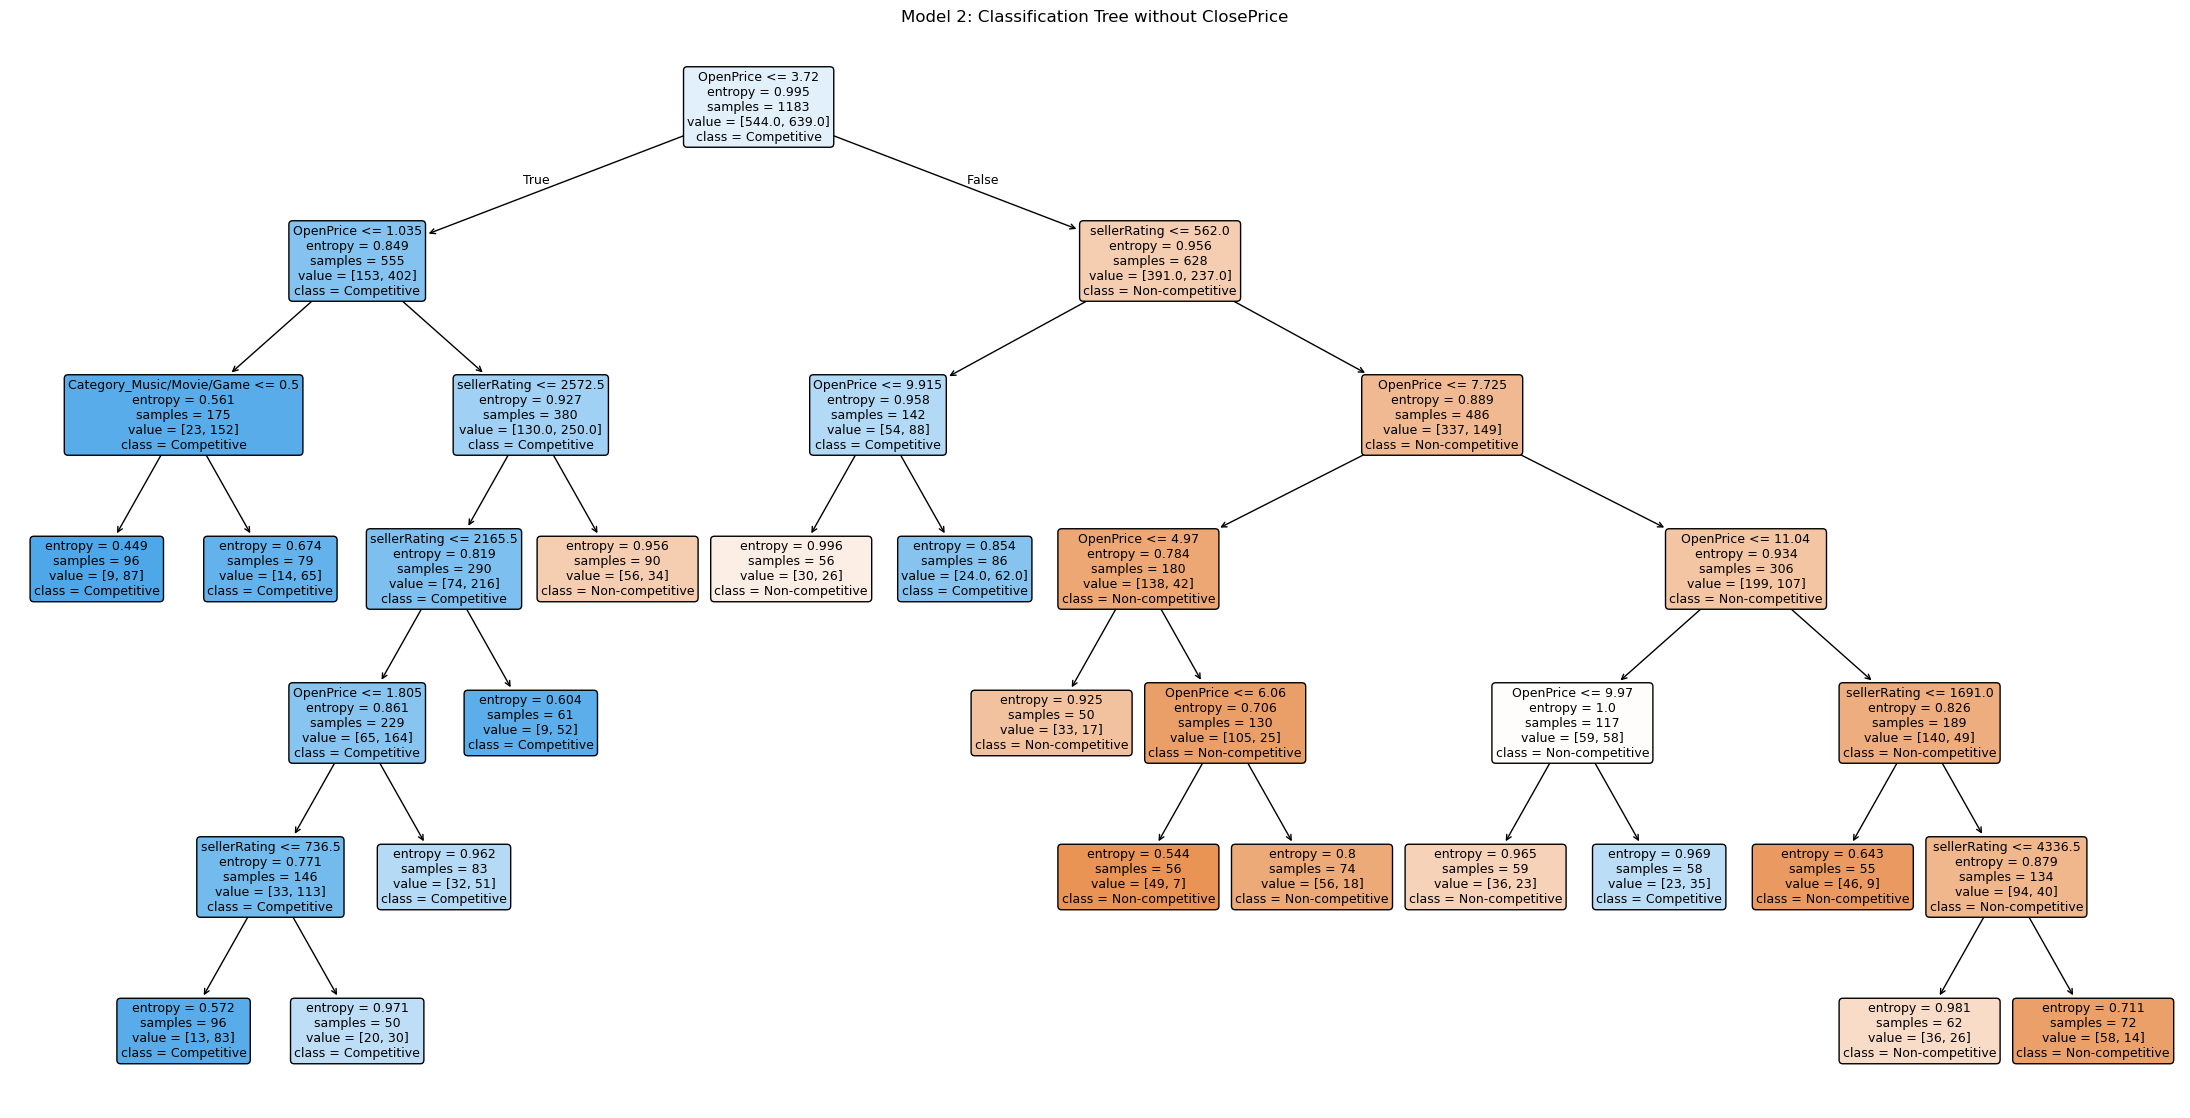

In [ ]:
# Visualizing Model 2 Tree
plt.figure(figsize=(28, 14))

plot_tree(
    model2,
    feature_names=X_train_model2.columns,
    class_names=['Non-competitive', 'Competitive'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Model 2: Classification Tree without ClosePrice')
plt.show()

In [ ]:
# Extracting decision rules from Model 2
rules_model2 = export_text(
    model2,
    feature_names=list(X_train_model2.columns),
    decimals=3
)

print(rules_model2)

|--- OpenPrice <= 3.720
|   |--- OpenPrice <= 1.035
|   |   |--- Category_Music/Movie/Game <= 0.500
|   |   |   |--- class: 1
|   |   |--- Category_Music/Movie/Game >  0.500
|   |   |   |--- class: 1
|   |--- OpenPrice >  1.035
|   |   |--- sellerRating <= 2572.500
|   |   |   |--- sellerRating <= 2165.500
|   |   |   |   |--- OpenPrice <= 1.805
|   |   |   |   |   |--- sellerRating <= 736.500
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- sellerRating >  736.500
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- OpenPrice >  1.805
|   |   |   |   |   |--- class: 1
|   |   |   |--- sellerRating >  2165.500
|   |   |   |   |--- class: 1
|   |   |--- sellerRating >  2572.500
|   |   |   |--- class: 0
|--- OpenPrice >  3.720
|   |--- sellerRating <= 562.000
|   |   |--- OpenPrice <= 9.915
|   |   |   |--- class: 0
|   |   |--- OpenPrice >  9.915
|   |   |   |--- class: 1
|   |--- sellerRating >  562.000
|   |   |--- OpenPrice <= 7.725
|   |   |   |--- OpenPrice <= 

In [ ]:
# Calculating feature importance
importance_model2 = pd.DataFrame({
    'Feature': X_train_model2.columns,
    'Importance': model2.feature_importances_
}).sort_values(by='Importance', ascending=False)

importance_model2.head(3)

,Feature,Importance
1,OpenPrice,0.662484
0,sellerRating,0.329886
15,Category_Music/Movie/Game,0.007630


# Model 2 information

It can now be appreciated that ClosePrice is not used in any of the decisions of the new decision tree. Once again, the criterion used for splitting has been entropy, and we have set a minimum node size of 50 and the random state 42.

In this new tree, the predictors used by the tree for decisions have been `OpenPrice`, `Category_Music/Movie/Game`, and `sellerRating`, where `OpenPrice` seems to be the main driver of auction competitiveness, and `SellerRating` looks to provide additional information within different price ranges.

In this new tree, none of the terminal nodes show an entropy value of 0, that is, no terminal node is complletely pure; however, some of the key decision rules are summarized below:

| Predictor | Model 1 feature importance | Model 2 feature importance |
|---|---|---:|
| `ClosePrice` | 54.14% | Excluded |
| `OpenPrice` | 40.57% | 66.25% |
| `SellerRating` | 5.30% | 32.99% |
| `Category` | 0% | 0.76% |
| `Other predictors` | 0% | 0% |

As can be seen from the comparison, Model 2 now places a substantially higher emphasis on `OpenPrice` compared to Model 1, as well as on `SellerRating`.

### Patterns in Model 2

1- Auctions with lower opening prices are more likely to receive multiple bids in the training data. This makes intutive sense, as lower opening prices reduce the initial financial barrier to participation.

    1.1- OpenPrice in the first split divides the 1183 observations according to whether the opening price is above or below 3720. Based on this split, the competitive rate decreases from 72.4% (402/555 auctions are competitive) to 37.7% (237/628 auctions are competitive) when moving from the lower opening price group to the higher opening price group.

2- Setting a very low opening price is associated with high auction competitiveness across item categories, however, the strength of this relationship varies slightly by category.

    2.1- For auctions with a opening price of 1.035 or less, the competitive rate increases further (i.e., 152/175=86.9%). Within this group, the model differentiates items belonging to the Music/Movie/Game category and all other categories. As a result, it can be appreciated that 82.3% of the auctions within the selected category are competitive, compared to the 90.6% rate of the other categories.

### Unexpected finding

1- The relationship between seller rating and auction competitiveness is nonlinear and depends on the opening price. 

    1.1- For auctions with an opening price between 1.035 and 3.720, seller rating becomes an important distinguishing factor. This is because sellers with a rating smaller or equal to 2572.5 show a competitive rate of 74.5%, compared to the 37.8% of the items with a seller rating bigger than 2572.5, and because of this, the predicted class changes from Competitive to Non-competitive. However, intuition says otherwise: We expect sellers with higher ratings to attract greater bidding activity because of their reputations. However, within the specified opening price, sellers with ratings above 2572.5 experience lower competitiveness.

    1.2- Moreover, within the opening price of 1.035 to 1.805, sellers with a rating smaller or equal to 736.5 show a competitive rate of 86.5%, compared to the 60.0% rate of the sellers with a rating between 736.5 and 2165.5. Once again, this shows that higher seller ratings are not consistently associated with greater competitiveness. However, the relationship is not strictly decreasing. Sellers with ratings between 2165.5 and 2572.5, within the broader opening price range of 1.035 to 3.720, achieve a competitive rate of 85.2%.

2- Lowering the opening price does not necessarily increase competitiveness.

    2.1- When the opening price exceeds 3.720, seller rating is used to distinguish between two groups: seller rating smaller or equal to 562, or greater. These show competitive rates of 62.0% and 30.7%, respectively, showing that sellers with lower ratings have a higher observed comppetitive rate within this price range. However, among the sellers with a rating of 562 or less, items with an opening price between 3.720 and 9.915 (included), show a competitive rate of 46.4%, compared to the 72.1% rate of the items with an opening price greater than 9.915. This shows that, contrary to the general relationship between opening price and competitiveness, higher opening prices are associated with greater competitiveness within this particular seller group.

### Decision rules for Model 2

| Opening price | Seller rating | Competitive rate | Prediction |
|---|---|---|---:|
| ≤ 1.035 | Any | 86.9% | Competitive |
| 1.035-3.720 | ≤ 2572.5 | 74.5% | Competitive |
|  | > 2572.5 | 37.8% | Non-competitive |
| 3.720-9.915 | ≤ 562 | 46.4% | Non-competitive |
| >9.915 | ≤ 562 | 72.1% | Competitive |
| 3.720-9.970 | > 562 | 27.2% | Non-competitive |
| 9.970-11.040 | > 562 | 60.3% | Competitive | 
| > 11.040 | > 562 | 25.9% | Non-competitive |


In [ ]:
# Identify the terminal node of each training observation
leaf_ids_model2 = model2.apply(X_train_model2)

# Extract decision paths
paths_model2 = model2.decision_path(X_train_model2)

rules_summary_model2 = []

for leaf_id in np.unique(leaf_ids_model2):

    mask = leaf_ids_model2 == leaf_id
    sample_id = np.where(mask)[0][0]
    node_ids = paths_model2[sample_id].indices

    conditions = []

    for node_id in node_ids:

        if node_id == leaf_id:
            continue

        feature = X_train_model2.columns[
            model2.tree_.feature[node_id]
        ]

        threshold = model2.tree_.threshold[node_id]
        value = X_train_model2.iloc[sample_id][feature]

        operator = "<=" if value <= threshold else ">"

        conditions.append(
            f"{feature} {operator} {threshold:.3f}"
        )

    rules_summary_model2.append({
        'Leaf': leaf_id,
        'Decision Rule': ' AND '.join(conditions),
        'Observations': mask.sum(),
        'Predicted Class': model2.predict(
            X_train_model2.iloc[[sample_id]]
        )[0],
        'Competitive Rate (%)': (y_train[mask] == 1).mean() * 100
    })

# Create the decision rules DataFrame
rules_table_model2 = pd.DataFrame(rules_summary_model2)

rules_table_model2 = rules_table_model2.sort_values(
    'Competitive Rate (%)',
    ascending=False
).reset_index(drop=True)

pd.set_option('display.max_colwidth', None)

display(rules_table_model2.round(2))

,Leaf,Decision Rule,Observations,Predicted Class,Competitive Rate (%)
0,3,OpenPrice <= 3.720 AND OpenPrice <= 1.035 AND Category_Music/Movie/Game <= 0.500,96,1,90.62
1,9,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating <= 2165.500 AND OpenPrice <= 1.805 AND sellerRating <= 736.500,96,1,86.46
2,12,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating > 2165.500,61,1,85.25
3,4,OpenPrice <= 3.720 AND OpenPrice <= 1.035 AND Category_Music/Movie/Game > 0.500,79,1,82.28
4,17,OpenPrice > 3.720 AND sellerRating <= 562.000 AND OpenPrice > 9.915,86,1,72.09
5,11,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating <= 2165.500 AND OpenPrice > 1.805,83,1,61.45
6,27,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice > 7.725 AND OpenPrice <= 11.040 AND OpenPrice > 9.970,58,1,60.34
7,10,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating <= 2165.500 AND OpenPrice <= 1.805 AND sellerRating > 736.500,50,1,60.00
8,16,OpenPrice > 3.720 AND sellerRating <= 562.000 AND OpenPrice <= 9.915,56,0,46.43
9,31,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice > 7.725 AND OpenPrice > 11.040 AND sellerRating > 1691.000 AND sellerRating <= 4336.500,62,0,41.94


In [ ]:
# The four most competitive auction profiles
most_competitive = rules_table_model2.nlargest(
    4, 'Competitive Rate (%)'
).copy()
# The four least competitive auction profiles
least_competitive = rules_table_model2.nsmallest(
    4, 'Competitive Rate (%)'
).copy()

display(most_competitive)
display(least_competitive)

,Leaf,Decision Rule,Observations,Predicted Class,Competitive Rate (%)
0,3,OpenPrice <= 3.720 AND OpenPrice <= 1.035 AND Category_Music/Movie/Game <= 0.500,96,1,90.625000
1,9,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating <= 2165.500 AND OpenPrice <= 1.805 AND sellerRating <= 736.500,96,1,86.458333
2,12,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating > 2165.500,61,1,85.245902
3,4,OpenPrice <= 3.720 AND OpenPrice <= 1.035 AND Category_Music/Movie/Game > 0.500,79,1,82.278481


,Leaf,Decision Rule,Observations,Predicted Class,Competitive Rate (%)
16,22,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice <= 7.725 AND OpenPrice > 4.970 AND OpenPrice <= 6.060,56,0,12.500000
15,29,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice > 7.725 AND OpenPrice > 11.040 AND sellerRating <= 1691.000,55,0,16.363636
14,32,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice > 7.725 AND OpenPrice > 11.040 AND sellerRating > 1691.000 AND sellerRating > 4336.500,72,0,19.444444
13,23,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice <= 7.725 AND OpenPrice > 4.970 AND OpenPrice > 6.060,74,0,24.324324


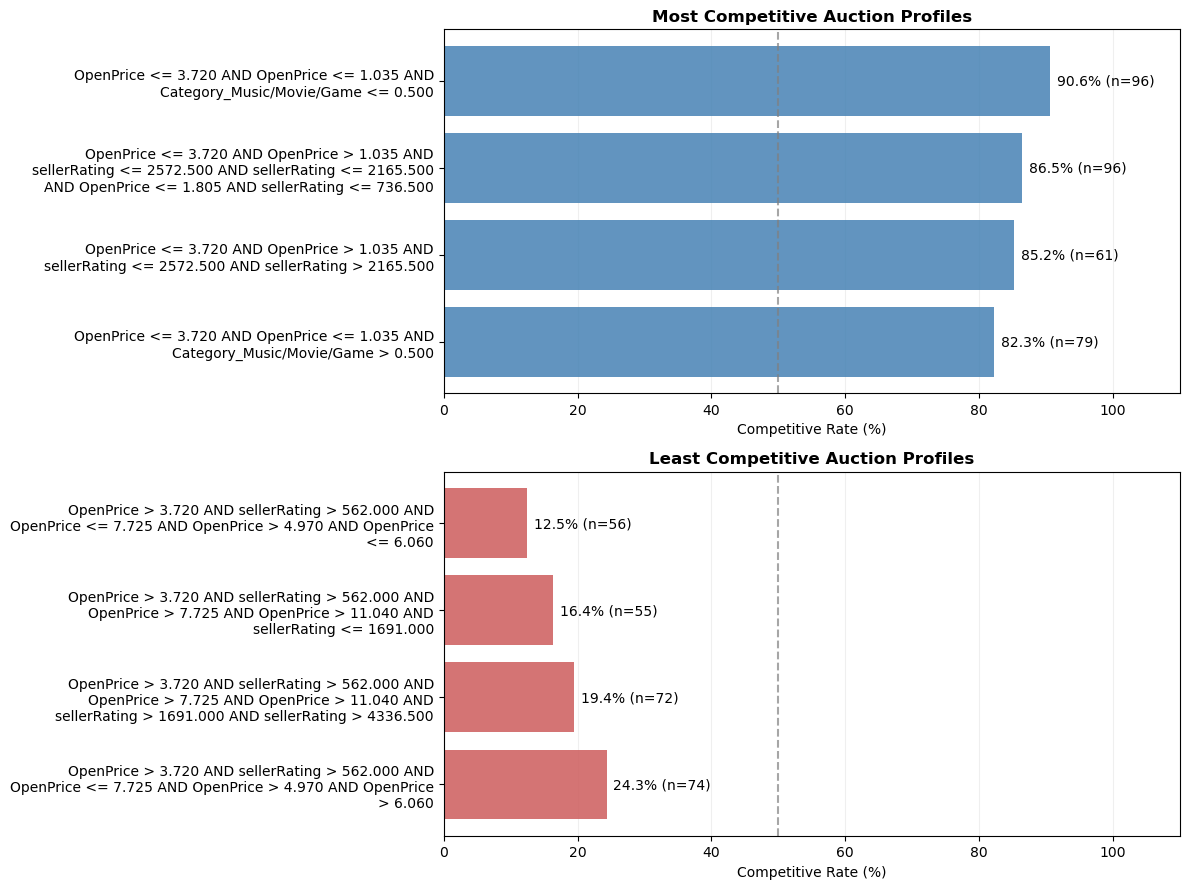

In [ ]:
import matplotlib.pyplot as plt
import textwrap

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

for ax, data, color, title in [
    (axes[0], most_competitive, 'steelblue',
     'Most Competitive Auction Profiles'),
    (axes[1], least_competitive, 'indianred',
     'Least Competitive Auction Profiles')
]:

    labels = [
        textwrap.fill(rule, width=55)
        for rule in data['Decision Rule']
    ]

    bars = ax.barh(
        labels,
        data['Competitive Rate (%)'],
        color=color,
        alpha=0.85
    )

    for bar, rate, n in zip(
        bars,
        data['Competitive Rate (%)'],
        data['Observations']
    ):
        ax.text(
            rate + 1,
            bar.get_y() + bar.get_height() / 2,
            f'{rate:.1f}% (n={n})',
            va='center',
            fontsize=10
        )

    ax.axvline(50, color='gray', linestyle='--', alpha=0.7)

    ax.set_xlim(0, 110)
    ax.set_xticks(range(0, 101, 20))
    ax.set_xlabel('Competitive Rate (%)')
    ax.set_title(title, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    'Model2_auction_profiles.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Decision rules

In [ ]:
# Extracting all internal decision nodes
splits_model2 = []

for node_id in range(model2.tree_.node_count):

    feature_id = model2.tree_.feature[node_id]

    # Exclude terminal nodes
    if feature_id >= 0:

        splits_model2.append({
            'Node': node_id,
            'Predictor': X_train_model2.columns[feature_id],
            'Threshold': model2.tree_.threshold[node_id],
            'Observations': model2.tree_.n_node_samples[node_id]
        })

splits_table_model2 = pd.DataFrame(splits_model2)

display(splits_table_model2.round(3))

,Node,Predictor,Threshold,Observations
0,0,OpenPrice,3.720,1183
1,1,OpenPrice,1.035,555
2,2,Category_Music/Movie/Game,0.500,175
3,5,sellerRating,2572.500,380
4,6,sellerRating,2165.500,290
5,7,OpenPrice,1.805,229
6,8,sellerRating,736.500,146
7,14,sellerRating,562.000,628
8,15,OpenPrice,9.915,142
9,18,OpenPrice,7.725,486


In [ ]:
quantitative_splits_model2 = splits_table_model2[
    splits_table_model2['Predictor'].isin(
        ['OpenPrice', 'sellerRating']
    )
]

display(quantitative_splits_model2.round(3))

,Node,Predictor,Threshold,Observations
0,0,OpenPrice,3.720,1183
1,1,OpenPrice,1.035,555
3,5,sellerRating,2572.500,380
4,6,sellerRating,2165.500,290
5,7,OpenPrice,1.805,229
6,8,sellerRating,736.500,146
7,14,sellerRating,562.000,628
8,15,OpenPrice,9.915,142
9,18,OpenPrice,7.725,486
10,19,OpenPrice,4.970,180
